In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [49]:
df = pd.read_csv("data/insurance.csv")

In [50]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [51]:
df.shape

(1338, 7)

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [53]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [54]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [55]:
df['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

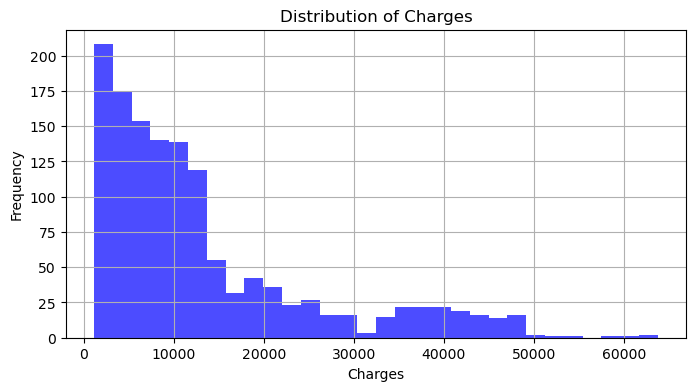

In [56]:
plt.figure(figsize=(8, 4))
plt.hist(df['charges'], bins=30, color='blue', alpha=0.7)
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.title('Distribution of Charges')
plt.grid()
plt.show()

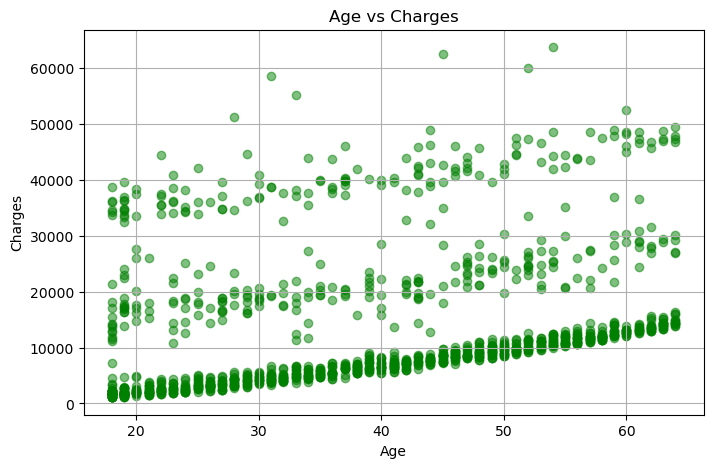

In [57]:
plt.figure(figsize=(8, 5))
plt.scatter(df['age'], df['charges'], color='green', alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Charges')
plt.title('Age vs Charges')
plt.grid()
plt.show()

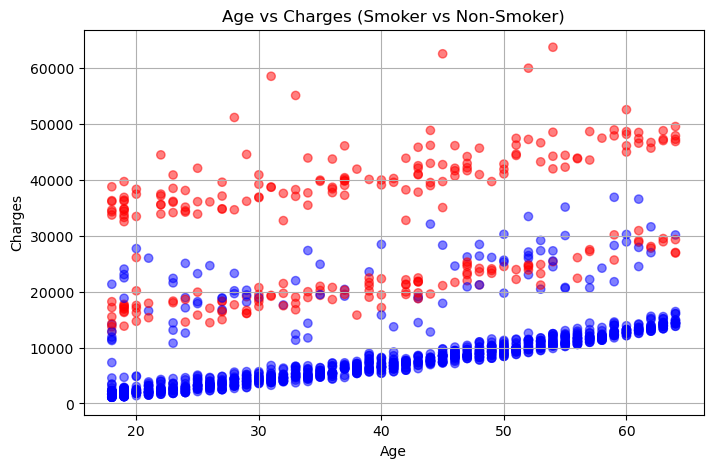

In [58]:
plt.figure(figsize=(8, 5))
colors = df['smoker'].map({'yes': 'red', 'no': 'blue'})
plt.scatter(df['age'], df['charges'], c=colors, alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Charges')
plt.title('Age vs Charges (Smoker vs Non-Smoker)')
plt.grid()
plt.show()

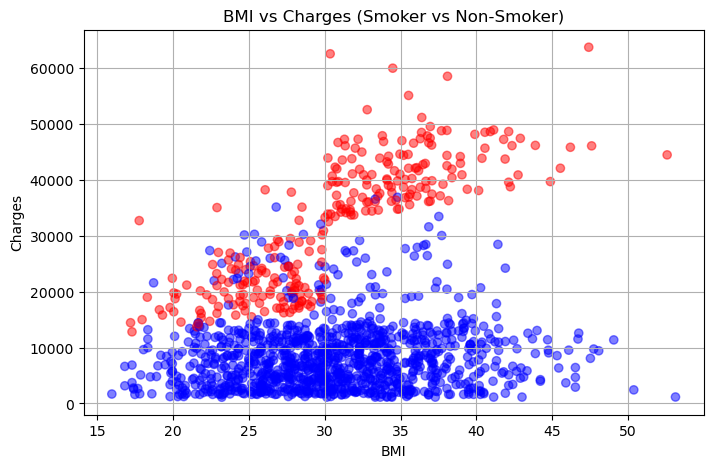

In [59]:
plt.figure(figsize=(8, 5))
plt.scatter(df['bmi'], df['charges'], c=colors, alpha=0.5)
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.title('BMI vs Charges (Smoker vs Non-Smoker)')
plt.grid()
plt.show()

In [60]:
df.groupby('smoker')['charges'].mean()

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

In [61]:
df.groupby('sex')['charges'].mean()

sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64

In [62]:
df.groupby('region')['charges'].mean()

region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64

In [63]:
df[['age', 'bmi', 'children', 'charges']].corr()

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


In [64]:
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [65]:
X = df_encoded.drop('charges', axis=1)
y= df_encoded['charges']

X.shape, y.shape

((1338, 8), (1338,))

In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=df['smoker'])

X_train.shape, X_test.shape

((1070, 8), (268, 8))

In [67]:
print(X_train['smoker_yes'].mean())
print(X_test['smoker_yes'].mean())

0.2046728971962617
0.20522388059701493


In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
from sklearn.preprocessing import add_dummy_feature

X_train_b = add_dummy_feature(X_train.values)
y_train_np = y_train.values.reshape(-1, 1)

theta = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train_np

theta.ravel()

array([-11465.24142848,    258.41903422,    324.67424821,    495.06633367,
         -240.27218606,  23859.0956788 ,   -439.99748507,  -1273.9130119 ,
         -863.11141187])

In [70]:
coef_table = pd.DataFrame({
    'feature': ['bias'] + list(X_train.columns),
    'coefficient': theta.ravel()
})
coef_table

,feature,coefficient
0,bias,-11465.241428
1,age,258.419034
2,bmi,324.674248
3,children,495.066334
4,sex_male,-240.272186
5,smoker_yes,23859.095679
6,region_northwest,-439.997485
7,region_southeast,-1273.913012
8,region_southwest,-863.111412


In [71]:
X_test_b = add_dummy_feature(X_test.values)
y_pred_manual = X_test_b @ theta

y_pred_manual[:5].ravel()

array([ 8034.02418857,  5644.60542239, 10705.70206866, 10638.65691559,
        2606.82659528])

In [72]:
y_test.values[:5]

array([ 6799.458  ,  4243.59005, 13415.0381 ,  6079.6715 , 22493.65964])

In [73]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

lin_reg.intercept_, lin_reg.coef_

(np.float64(-11465.241428482459),
 array([  258.41903422,   324.67424821,   495.06633367,  -240.27218606,
        23859.0956788 ,  -439.99748507, -1273.9130119 ,  -863.11141187]))

In [74]:
y_pred = lin_reg.predict(X_test)
np.allclose(y_pred, y_pred_manual.ravel())

True

In [75]:
from sklearn.metrics import mean_squared_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('RMSE:', rmse)
print('R2:', r2)

RMSE: 5581.331744261831
R2: 0.7888523049204451


In [76]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_test)
print('Dummy Regressor RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_dummy)))
print('Dummy Regressor R2:', r2_score(y_test, y_pred_dummy))

Dummy Regressor RMSE: 12146.539891180542
Dummy Regressor R2: -3.6456660719830225e-05


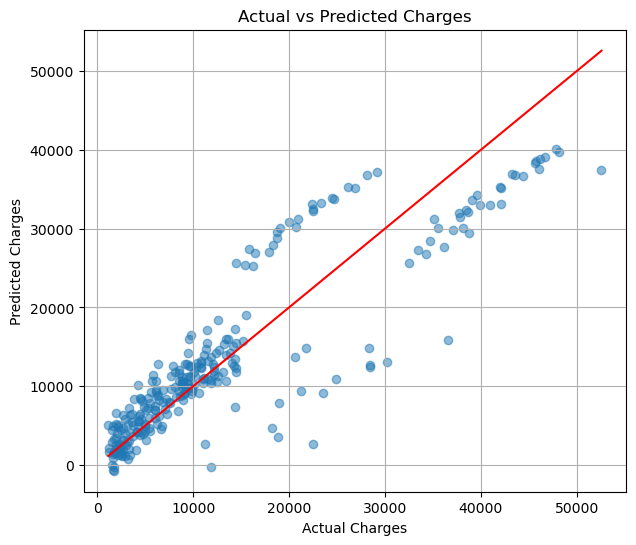

In [77]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r-')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
plt.grid()
plt.show()

In [80]:
X_train_sb = add_dummy_feature(X_train_scaled)
X_test_sb = add_dummy_feature(X_test_scaled)
y_tr = y_train.values.reshape(-1, 1)

m = len(X_train_sb)

def test_rmse(theta):
    pred = X_test_sb @ theta
    return np.sqrt(mean_squared_error(y_test, pred))


In [81]:
eta = 0.1
n_epochs = 1000

np.random.seed(42)
theta_bgd = np.random.randn(X_train_sb.shape[1], 1)
losses = []

for epoch in range(n_epochs):
    gradient = 2 / m * X_train_sb.T @ (X_train_sb @ theta_bgd - y_tr)
    theta_bgd = theta_bgd - eta * gradient
    losses.append(np.mean((X_train_sb @ theta_bgd - y_tr) ** 2))

print('Batch GD test RMSE:', test_rmse(theta_bgd))

Batch GD test RMSE: 5581.331744261827


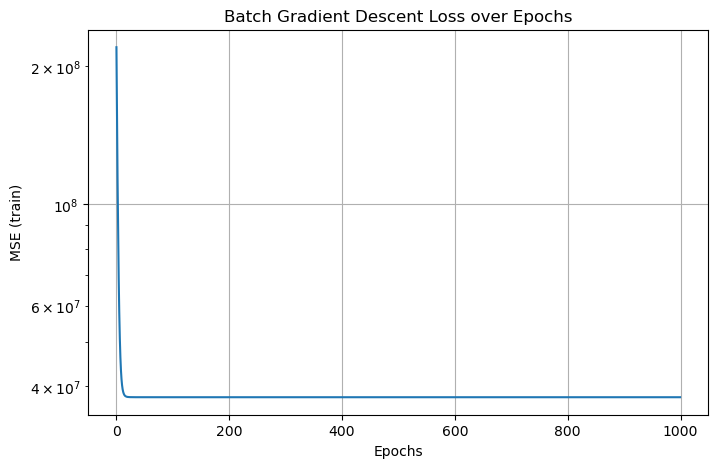

In [87]:
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.xlabel('Epochs')
plt.ylabel('MSE (train)')
plt.yscale('log')
plt.title('Batch Gradient Descent Loss over Epochs')
plt.grid()
plt.show()

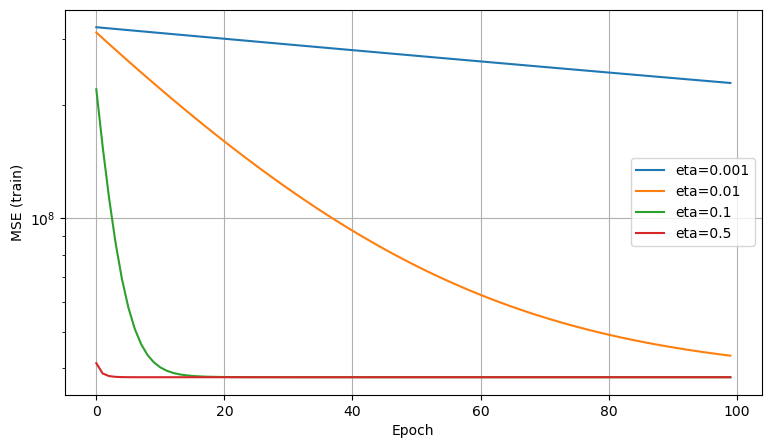

In [88]:
def run_bgd(eta, n_epochs=100):
    np.random.seed(42)
    theta = np.random.randn(X_train_sb.shape[1], 1)
    errs = []
    for _ in range(n_epochs):
        grad = 2 / m * X_train_sb.T @ (X_train_sb @ theta - y_tr)
        theta = theta - eta * grad
        errs.append(np.mean((X_train_sb @ theta - y_tr) ** 2))
    return errs

plt.figure(figsize=(9, 5))
for eta_try in [0.001, 0.01, 0.1, 0.5]:
    plt.plot(run_bgd(eta_try), label=f'eta={eta_try}')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE (train)')
plt.legend()
plt.grid()
plt.show()

In [93]:
n_epochs = 50
eta = 0.01

np.random.seed(42)
theta_sgd = np.random.randn(X_train_sb.shape[1], 1)

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_train_sb[random_index : random_index + 1]
        yi = y_tr[random_index : random_index + 1]
        gradient = 2 * xi.T @ (xi @ theta_sgd - yi)
        theta_sgd = theta_sgd - eta * gradient

print('SGD test RMSE:', test_rmse(theta_sgd))

SGD test RMSE: 6247.432137587259


In [94]:
from math import ceil

n_epochs = 100
eta = 0.05
minibatch_size = 32
n_batches = ceil(m / minibatch_size)

np.random.seed(42)
theta_mbgd = np.random.randn(X_train_sb.shape[1], 1)

for epoch in range(n_epochs):
    shuffled = np.random.permutation(m)
    X_shuf = X_train_sb[shuffled]
    y_shuf = y_tr[shuffled]
    for i in range(n_batches):
        idx = i * minibatch_size
        xi = X_shuf[idx : idx + minibatch_size]
        yi = y_shuf[idx : idx + minibatch_size]
        gradient = 2 / len(xi) * xi.T @ (xi @ theta_mbgd - yi)
        theta_mbgd = theta_mbgd - eta * gradient

print('Mini-batch test RMSE:', test_rmse(theta_mbgd))

Mini-batch test RMSE: 5668.197449370766


In [95]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01, n_iter_no_change=100, random_state=42)
sgd_reg.fit(X_train_scaled, y_train)

y_pred_sgd = sgd_reg.predict(X_test_scaled)
print('SGD Regressor RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_sgd)))

SGD Regressor RMSE: 5583.680532392461


In [96]:
lin_reg_scaled = LinearRegression().fit(X_train_scaled, y_train)
print('Normal equation RMSE:',
      np.sqrt(mean_squared_error(y_test, lin_reg_scaled.predict(X_test_scaled))))

Normal equation RMSE: 5581.331744261827


In [97]:
compare = pd.DataFrame({
    'feature': ['bias'] + list(X_train.columns),
    'Normal Eq': np.r_[lin_reg_scaled.intercept_, lin_reg_scaled.coef_],
    'Batch GD': theta_bgd.ravel(),
    'SGD': theta_sgd.ravel(),
    'Mini-batch': theta_mbgd.ravel(),
})
compare.round(1)

,feature,Normal Eq,Batch GD,SGD,Mini-batch
0,bias,13285.1,13285.1,13720.1,13219.3
1,age,3626.0,3626.0,4150.6,3745.8
2,bmi,1962.1,1962.1,2254.3,2180.5
3,children,598.9,598.9,-1232.3,412.4
4,sex_male,-120.1,-120.1,-342.6,-673.0
5,smoker_yes,9626.2,9626.2,9264.5,10397.3
6,region_northwest,-188.7,-188.7,-394.9,-88.3
7,region_southeast,-566.9,-566.9,-1354.1,-697.0
8,region_southwest,-368.7,-368.7,583.2,-440.2


In [98]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

poly2 = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression())
poly2.fit(X_train, y_train)

pred_train = poly2.predict(X_train)
pred_test = poly2.predict(X_test)

print('Train RMSE:', np.sqrt(mean_squared_error(y_train, pred_train)))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, pred_test)))
print('Test R2:', r2_score(y_test, pred_test))

Train RMSE: 4779.241647678508
Test RMSE: 4604.474126722374
Test R2: 0.8562953752652195


In [99]:
degrees = [1, 2, 3, 4, 5]
train_rmse, test_rmse_list = [], []

for d in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    train_rmse.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
    test_rmse_list.append(np.sqrt(mean_squared_error(y_test, model.predict(X_test))))
    print(f'degree={d}  train={train_rmse[-1]:.0f}  test={test_rmse_list[-1]:.0f}')

degree=1  train=6155  test=5581
degree=2  train=4779  test=4604
degree=3  train=4600  test=4821
degree=4  train=4257  test=6873
degree=5  train=3653  test=27378


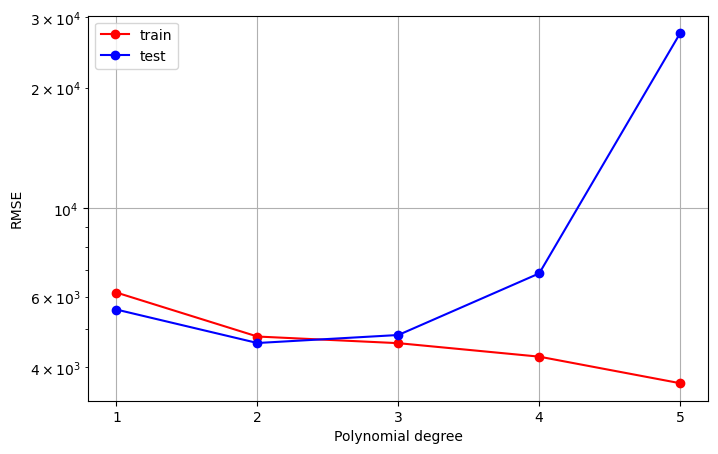

In [100]:
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rmse, 'r-o', label='train')
plt.plot(degrees, test_rmse_list, 'b-o', label='test')
plt.xlabel('Polynomial degree')
plt.ylabel('RMSE')
plt.yscale('log')
plt.xticks(degrees)
plt.legend()
plt.grid()
plt.show()

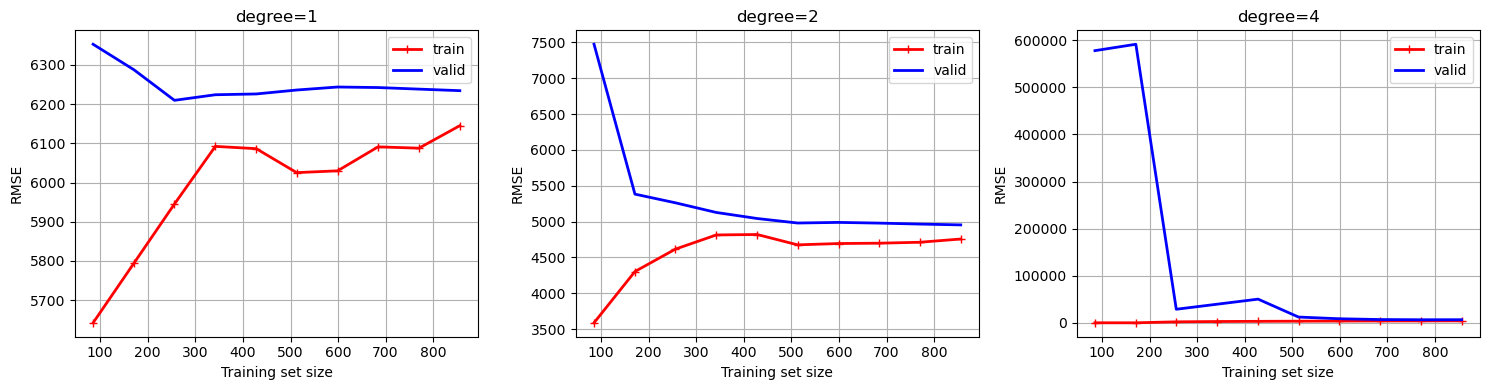

In [101]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(degree):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    train_sizes, train_scores, valid_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=np.linspace(0.1, 1.0, 10), cv=5,
        scoring='neg_root_mean_squared_error'
    )
    plt.plot(train_sizes, -train_scores.mean(axis=1), 'r-+', linewidth=2, label='train')
    plt.plot(train_sizes, -valid_scores.mean(axis=1), 'b-', linewidth=2, label='valid')
    plt.title(f'degree={degree}')
    plt.xlabel('Training set size')
    plt.ylabel('RMSE')
    plt.legend()
    plt.grid()

plt.figure(figsize=(15, 4))
for i, d in enumerate([1, 2, 4]):
    plt.subplot(1, 3, i + 1)
    plot_learning_curve(d)
plt.tight_layout()
plt.show()

In [102]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

def rmse(model, X_a, y_a):
    return np.sqrt(mean_squared_error(y_a, model.predict(X_a)))

base = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    StandardScaler(),
    LinearRegression()
)
base.fit(X_train, y_train)

print('Base model (degree=4) -> train:', rmse(base, X_train, y_train),
      ' test:', rmse(base, X_test, y_test))

Base model (degree=4) -> train: 4256.785497462176  test: 6873.219976000553


In [104]:
ridge = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    StandardScaler(),
    Ridge(alpha=10)
)
ridge.fit(X_train, y_train)

print('Ridge -> train:', rmse(ridge, X_train, y_train),
      ' test:', rmse(ridge, X_test, y_test))

Ridge -> train: 4566.985476754888  test: 4934.093301066761


alpha=0.01    train=4312  test=5734
alpha=0.1     train=4370  test=5496
alpha=1       train=4449  test=5241
alpha=10      train=4567  test=4934
alpha=100     train=4728  test=4783
alpha=1000    train=5122  test=4825


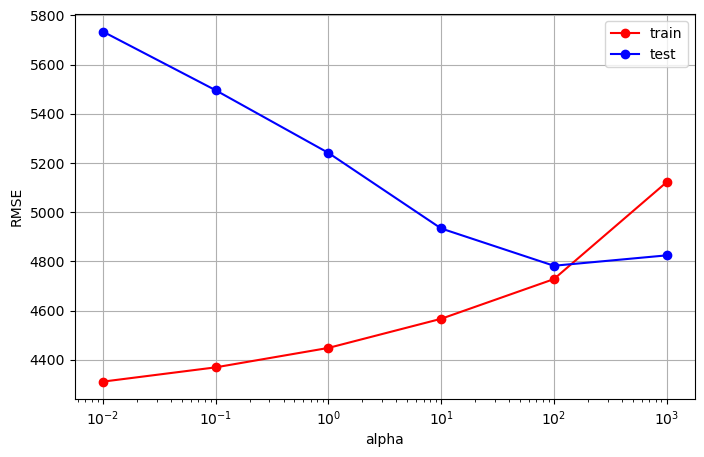

In [105]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]
tr_err, te_err = [], []

for a in alphas:
    m_ = make_pipeline(
        PolynomialFeatures(degree=4, include_bias=False),
        StandardScaler(),
        Ridge(alpha=a)
    )
    m_.fit(X_train, y_train)
    tr_err.append(rmse(m_, X_train, y_train))
    te_err.append(rmse(m_, X_test, y_test))
    print(f'alpha={a:<7} train={tr_err[-1]:.0f}  test={te_err[-1]:.0f}')

plt.figure(figsize=(8, 5))
plt.plot(alphas, tr_err, 'r-o', label='train')
plt.plot(alphas, te_err, 'b-o', label='test')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.legend()
plt.grid()
plt.show()

In [107]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    StandardScaler(),
    Ridge()
)

param_grid = {'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]}
grid = GridSearchCV(pipe, param_grid, cv=5,
                    scoring='neg_root_mean_squared_error')
grid.fit(X_train, y_train)

print('Best alpha:', grid.best_params_)
print('CV RMSE:', -grid.best_score_)
print('Test RMSE:', rmse(grid.best_estimator_, X_test, y_test))

Best alpha: {'ridge__alpha': 100}
CV RMSE: 5098.851135981847
Test RMSE: 4782.539607664092


In [109]:
lasso = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    StandardScaler(),
    Lasso(alpha=50, max_iter=100000)
)
lasso.fit(X_train, y_train)

print('Lasso -> train:', rmse(lasso, X_train, y_train),
      ' test:', rmse(lasso, X_test, y_test))

coefs = lasso[-1].coef_
print('Total coefficients:', len(coefs))
print('Zero coefficients:', np.sum(coefs == 0))
print('Non-zero coefficients:', np.sum(coefs != 0))

Lasso -> train: 4769.717507994534  test: 4691.436695068851
Total coefficients: 494
Zero coefficients: 430
Non-zero coefficients: 64


In [112]:
poly_names = lasso[0].get_feature_names_out(X_train.columns)
kept = pd.DataFrame({'feature': poly_names, 'coef': coefs})
kept = kept[kept['coef'] != 0].sort_values('coef', key=abs, ascending=False)
kept.head(10)

,feature,coef
83,bmi^2 smoker_yes,9199.618607
8,age^2,2461.652941
289,bmi^3 region_southeast,-762.118603
44,age^3,573.991761
19,bmi smoker_yes,572.888756
240,age children smoker_yes region_northwest,543.003826
304,bmi^2 smoker_yes region_southeast,-527.563844
305,bmi^2 smoker_yes region_southwest,497.543933
2,children,495.046786
303,bmi^2 smoker_yes region_northwest,475.138964


In [113]:
for a in [1, 10, 50, 200, 1000]:
    m_ = make_pipeline(
        PolynomialFeatures(degree=4, include_bias=False),
        StandardScaler(),
        Lasso(alpha=a, max_iter=100000)
    )
    m_.fit(X_train, y_train)
    nz = np.sum(m_[-1].coef_ != 0)
    print(f'alpha={a:<5} zero coefficients={nz:<4} test RMSE={rmse(m_, X_test, y_test):.0f}')

alpha=1     zero coefficients=238  test RMSE=5264
alpha=10    zero coefficients=111  test RMSE=4830
alpha=50    zero coefficients=64   test RMSE=4691
alpha=200   zero coefficients=27   test RMSE=4675
alpha=1000  zero coefficients=9    test RMSE=4918


In [114]:
enet = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    StandardScaler(),
    ElasticNet(alpha=50, l1_ratio=0.5, max_iter=100000)
)
enet.fit(X_train, y_train)

print('ElasticNet -> train:', rmse(enet, X_train, y_train),
      ' test:', rmse(enet, X_test, y_test))

ElasticNet -> train: 7425.369033779492  test: 7256.818242867247


In [115]:
results = pd.DataFrame({
    'Model': ['Linear (deg=1)', 'Poly deg=4 (no penalty)', 'Ridge', 'Lasso', 'ElasticNet'],
    'Test RMSE': [
        rmse(make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train), X_test, y_test),
        rmse(base, X_test, y_test),
        rmse(ridge, X_test, y_test),
        rmse(lasso, X_test, y_test),
        rmse(enet, X_test, y_test),
    ]
})
results.round(0)

,Model,Test RMSE
0,Linear (deg=1),5581.0
1,Poly deg=4 (no penalty),6873.0
2,Ridge,4934.0
3,Lasso,4691.0
4,ElasticNet,7257.0
